# Assignment 1 (Week 5) — Motor parameter identification

**CS413 Robotics, NewUU** · Fayozbek Yusupov · Student ID: 240061

In this assignment I identify the parameters of the two drive motors of my TRIK robot from my own measurements. The data were recorded with two TRIK Studio visual programs (`motor_steps.qrs` and `motor_signal.qrs`), and all processing is done below on the raw files in `motor_data/`.

## 1. Motor model

If the armature inductance is neglected, a lightly loaded DC motor is a first-order system in angular velocity:

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega$$

| Symbol | Meaning (my words) | Unit |
|---|---|---|
| $U$ | voltage on the motor. TRIK sets PWM in %, so $U = \text{PWM}/100 \cdot U_{battery}$ | V |
| $\theta$, $\omega$ | angle of the wheel shaft and how fast it turns | rad, rad/s |
| $\omega_{ss}$ | the constant speed the motor reaches after some time at a fixed $U$ | rad/s |
| $T_m$ | how fast the motor speeds up: after $T_m$ seconds it has 63 % of $\omega_{ss}$ | s |
| $k_e$ | back-EMF constant: how many volts are needed for 1 rad/s of steady speed | V·s/rad |

**Step response.** At $t=0$ a constant $U$ is applied to a motor at rest ($\omega(0)=0$, $\theta(0)=0$). With $\omega_{ss}=U/k_e$ the equation becomes $T_m\,\dot\omega + \omega = \omega_{ss}$. Its solution is the free part $Ce^{-t/T_m}$ plus the constant part $\omega_{ss}$; from $\omega(0)=0$ we get $C=-\omega_{ss}$:

$$\omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right)$$

The angle is the integral of the speed:

$$\theta(t) = \int_0^t \omega_{ss}\left(1 - e^{-s/T_m}\right)ds = \omega_{ss}\left(t + T_m e^{-t/T_m} - T_m\right) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right)$$

For large $t$ the exponent disappears and $\theta \approx \omega_{ss}(t - T_m)$: a straight line with slope $\omega_{ss}$ that is shifted by $T_m$. So one step gives two numbers: $\omega_{ss}$ (slope) and $T_m$ (shift).

**Assumptions of the model and how my data test them**

| Assumption | What would break it in the data | Where I check it |
|---|---|---|
| No inductance | a delay or overshoot at the very start of a step | step fits (sec. 4.2) |
| Linear viscous friction | $\omega_{ss}$ not proportional to $U$, a dead zone at small PWM | speed-from-PWM plot (sec. 4.3) |
| Constant load | different $T_m$ at different speeds or directions | $T_m$-from-PWM plot (sec. 4.3) |
| Constant battery voltage within a run | the same PWM gives a lower speed later | battery readings, repeated run (sec. 5) |

## 2. Test signals

| Signal | Why I used it |
|---|---|
| Step series −100 … +100 % (step 10 %), 2 s on + 1 s off | $\omega_{ss}$ and $T_m$ at every level, asymmetry, saturation, coasting |
| Fine step series −9 … +9 % (step 1 %) | the dead zone: at 10 % both wheels already turn, so the threshold is below 10 % |
| Square wave, $A = 60\%$, $P = 1$ s, 8 s | repeated accelerations and direction reversals, gear backlash, $T_m$ in both directions in one run |
| Chirp, $A = 60\%$, 0.2 → 5 Hz over 8 s | frequency response: the amplitude must fall and the lag grow as frequency increases (direct check of $T_m$) |

Design rules: the half period of the square wave (0.5 s) is several times $T_m$ (expected 0.05–0.4 s); the chirp starts well below $1/(2\pi T_m)$ (≈ 0.4–3 Hz) and ends above it; both signals cross zero, so both directions and the dead zone are in one record; the amplitude 60 % is below 80 %, so the model is not tested only in saturation.

Formulas used in the program ($\tau$ = time from the start of the signal, $\text{frac}(x)=x-\lfloor x\rfloor$):

* square: $u = A \cdot \text{sgn}(0.5 - \text{frac}(\tau/P))$
* chirp: $u = A \sin\left(2\pi\left(f_0 \tau + (f_1-f_0)\tau^2/(2T)\right)\right)$

## 3. Data collection

Both programs are built from blocks in TRIK Studio (no JavaScript or Python text). TRIK Studio has no `round()`, so I used `floor(u + 0.5)`, and `frac` is `x - floor(x)`; `pi` is a built-in constant.

* **`motor_steps.qrs`** — Remove File → Clear Encoder → 3 s with the motor off (zero-drift check) → loop over `level` from −100 to 100: if `level != 0`, the motor gets `level` for 2 s, then 0 for 1 s (coasting). Every cycle writes `angle,time,PWM` to the file. For the fine series only the start, end and step of `level` were changed (−9 … 9, step 1).
* **`motor_signal.qrs`** — the same logging, but the PWM is recalculated every cycle from the chosen formula (`kind = 1` square, `kind = 4` chirp), then 1 s of coasting is logged.
* Ports: **left motor M4** with encoder E4, **right motor M3** with encoder E3 (checked by watching which wheel turns). For the right motor only the ports and the file name were changed.
* The robot was held in the air by hand, so the wheels spun freely (no load). The step series was run twice on M4 to check repeatability.
* The [Timer] delay is 5 ms in all loops; the real sampling interval is longer because writing to the file takes time (sec. 5).
* The battery voltage was read on the TRIK display before and after every run (`motor_data/battery.txt`). It showed 11.2 V every time.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

if not os.path.isdir('motor_data'):
    os.system('git clone -q https://github.com/KINGLABBOK/CS413-Robotics.git')
    os.chdir('CS413-Robotics/final')
print(sorted(os.listdir('motor_data')))

['battery.txt', 'chirp_M3.txt', 'chirp_M4.txt', 'deadzone_M3.txt', 'deadzone_M4.txt', 'square_M3.txt', 'square_M4.txt', 'steps_M3.txt', 'steps_M4.txt', 'steps_M4_repeat.txt']


## 4. Data processing

### 4.1 Loading and SI conversion

Each line of my files is `angle (deg), time (ms), PWM (%)`, so the loading line of the course notebook is changed to this column order. Time is converted to seconds and the angle to radians.

In [2]:
def load(name):
    angle, t, pwm = np.loadtxt('motor_data/' + name, delimiter=',', unpack=True)
    return angle * np.pi / 180, t / 1000, pwm

battery = {}
for line in open('motor_data/battery.txt'):
    p = line.strip().split(',')
    if len(p) == 3 and p[0].endswith('.txt'):
        battery[p[0]] = (float(p[1]), float(p[2]))

def U_bat(name):
    return sum(battery[name]) / 2

step_files = {'M4': 'steps_M4.txt', 'M4 repeat': 'steps_M4_repeat.txt', 'M3': 'steps_M3.txt'}
fine_files = {'M4': 'deadzone_M4.txt', 'M3': 'deadzone_M3.txt'}
signal_files = ['square_M4.txt', 'square_M3.txt', 'chirp_M4.txt', 'chirp_M3.txt']
data = {k: load(f) for k, f in step_files.items()}
fine = {k: load(f) for k, f in fine_files.items()}

for f in list(step_files.values()) + list(fine_files.values()) + signal_files:
    th, t, pwm = load(f)
    print(f'{f:20s} {len(t):5d} samples, {t[-1] - t[0]:5.1f} s, PWM {pwm.min():4.0f}..{pwm.max():3.0f} %, '
          f'battery {battery[f][0]:.1f} -> {battery[f][1]:.1f} V')

steps_M4.txt          3076 samples,  63.2 s, PWM -100..100 %, battery 11.2 -> 11.2 V
steps_M4_repeat.txt   3108 samples,  63.2 s, PWM -100..100 %, battery 11.2 -> 11.2 V
steps_M3.txt          3114 samples,  63.2 s, PWM -100..100 %, battery 11.2 -> 11.2 V
deadzone_M4.txt       2741 samples,  57.2 s, PWM   -9..  9 %, battery 11.2 -> 11.2 V
deadzone_M3.txt       2753 samples,  57.2 s, PWM   -9..  9 %, battery 11.2 -> 11.2 V
square_M4.txt          327 samples,   9.0 s, PWM  -60.. 60 %, battery 11.2 -> 11.2 V
square_M3.txt          326 samples,   9.0 s, PWM  -60.. 60 %, battery 11.2 -> 11.2 V
chirp_M4.txt           326 samples,   9.0 s, PWM  -60.. 60 %, battery 11.2 -> 11.2 V
chirp_M3.txt           324 samples,   9.0 s, PWM  -60.. 60 %, battery 11.2 -> 11.2 V


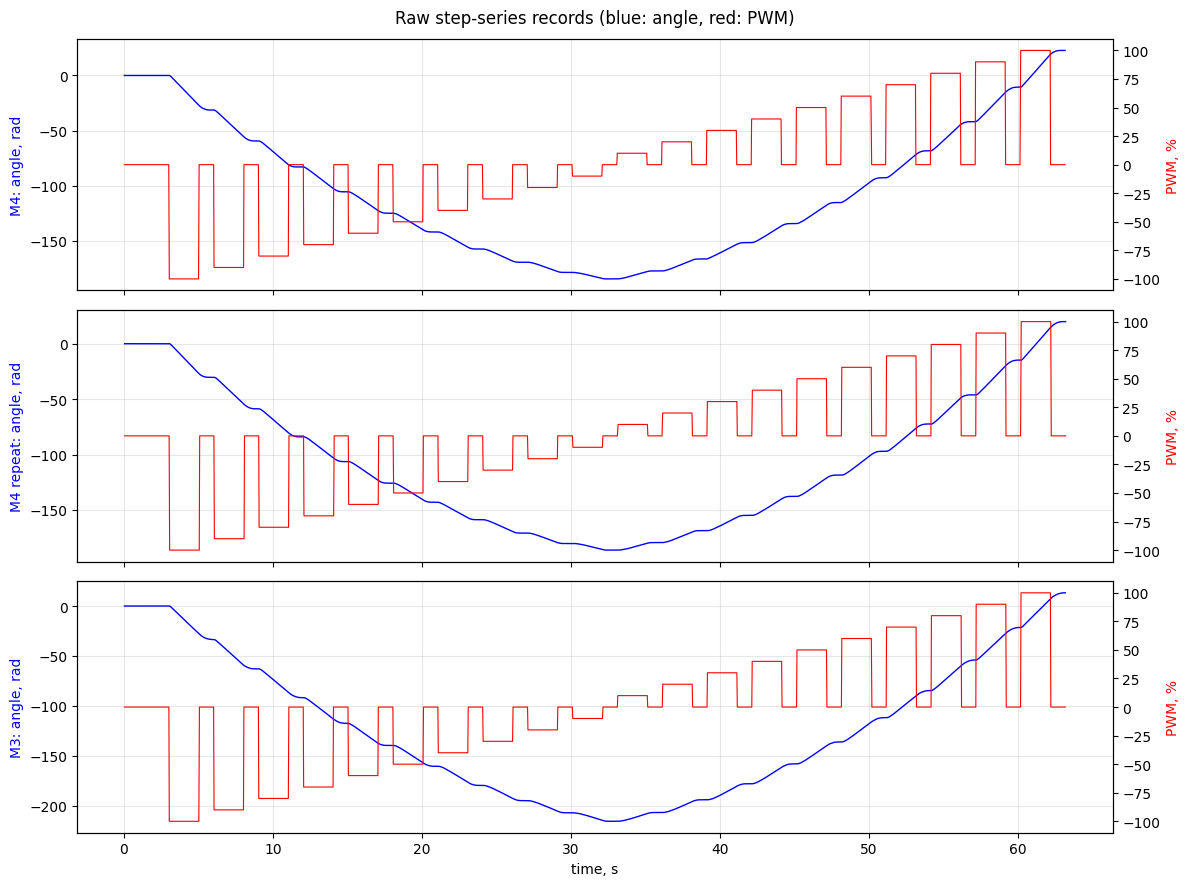

In [3]:
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (k, (th, t, pwm)) in zip(axs, data.items()):
    ax.plot(t, th, 'b-', lw=1)
    ax.set_ylabel(k + ': angle, rad', color='b')
    ax2 = ax.twinx()
    ax2.plot(t, pwm, 'r-', lw=0.8)
    ax2.set_ylabel('PWM, %', color='r')
    ax.grid(alpha=0.3)
axs[-1].set_xlabel('time, s')
fig.suptitle('Raw step-series records (blue: angle, red: PWM)')
plt.tight_layout()
plt.show()

### 4.2 Step responses

The file is split into segments where the PWM column is constant. For every step segment (PWM ≠ 0) the initial angle and time are subtracted and the notebook's model is fitted with `optimize.curve_fit`. In the fine series (±1 … ±9 %) the start of a step is not a clean first-order curve, so there $\omega_{ss}$ is the average speed over the last second of the step, and a level counts as "not moving" if the wheel turned less than 10° in 2 s.

In [4]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def split(pwm):
    edges = np.flatnonzero(np.diff(pwm) != 0) + 1
    return list(zip(np.r_[0, edges], np.r_[edges, len(pwm)]))

def fit_steps(theta, t, pwm):
    rows = []
    for s, e in split(pwm):
        level = pwm[s]
        if level == 0:
            continue
        ts = t[s:e] - t[s]
        th = theta[s:e] - theta[s]
        moved = abs(th[-1]) > np.radians(10)
        if moved:
            popt, pcov = optimize.curve_fit(model, ts, th, p0=[np.sign(level) * 8, 0.1],
                                            bounds=([-60, 0.005], [60, 2]))
            err = np.sqrt(np.diag(pcov))
        else:
            popt, err = [0.0, np.nan], [np.nan, np.nan]
        rows.append(dict(level=level, w=popt[0], w_err=err[0], T=popt[1], T_err=err[1],
                         moved=moved, t=ts, th=th, start=s, end=e))
    return rows

def fit_fine(theta, t, pwm):
    rows = []
    for s, e in split(pwm):
        level = pwm[s]
        if level == 0:
            continue
        ts = t[s:e] - t[s]
        th = theta[s:e] - theta[s]
        moved = abs(th[-1]) > np.radians(10)
        w = np.polyfit(ts[ts > 1.0], th[ts > 1.0], 1)[0] if moved else 0.0
        rows.append(dict(level=level, w=w, moved=moved))
    return rows

steps = {k: fit_steps(*data[k]) for k in data}
steps_fine = {k: fit_fine(*fine[k]) for k in fine}

for k in steps:
    print(k)
    print('  PWM %   w_ss, rad/s        T_m, s')
    for r in steps[k]:
        print(f"  {r['level']:5.0f}   {r['w']:7.2f} ± {r['w_err']:.2f}   {r['T']:.3f} ± {r['T_err']:.3f}")
for k in steps_fine:
    print(k, 'fine series, w_ss in rad/s (0 = not moving):')
    print('  ' + '  '.join(f"{r['level']:+.0f}%: {r['w']:.2f}" for r in steps_fine[k]))

M4
  PWM %   w_ss, rad/s        T_m, s
   -100    -13.95 ± 0.00   0.045 ± 0.000
    -90    -12.62 ± 0.00   0.076 ± 0.000
    -80    -11.50 ± 0.00   0.113 ± 0.000
    -70    -10.29 ± 0.01   0.085 ± 0.001
    -60     -9.24 ± 0.01   0.152 ± 0.001
    -50     -8.37 ± 0.01   0.190 ± 0.001
    -40     -7.67 ± 0.00   0.202 ± 0.001
    -30     -6.23 ± 0.00   0.231 ± 0.001
    -20     -4.98 ± 0.00   0.307 ± 0.001
    -10     -3.38 ± 0.00   0.352 ± 0.001
     10      3.93 ± 0.00   0.292 ± 0.001
     20      5.63 ± 0.00   0.269 ± 0.001
     30      6.80 ± 0.01   0.058 ± 0.002
     40      8.46 ± 0.01   0.206 ± 0.001
     50      9.23 ± 0.01   0.201 ± 0.001
     60     10.10 ± 0.01   0.097 ± 0.002
     70     11.29 ± 0.01   0.136 ± 0.001
     80     12.56 ± 0.01   0.111 ± 0.000
     90     13.80 ± 0.01   0.075 ± 0.000
    100     15.29 ± 0.00   0.048 ± 0.000
M4 repeat
  PWM %   w_ss, rad/s        T_m, s
   -100    -13.96 ± 0.00   0.033 ± 0.000
    -90    -12.65 ± 0.00   0.074 ± 0.000
    -80    -1

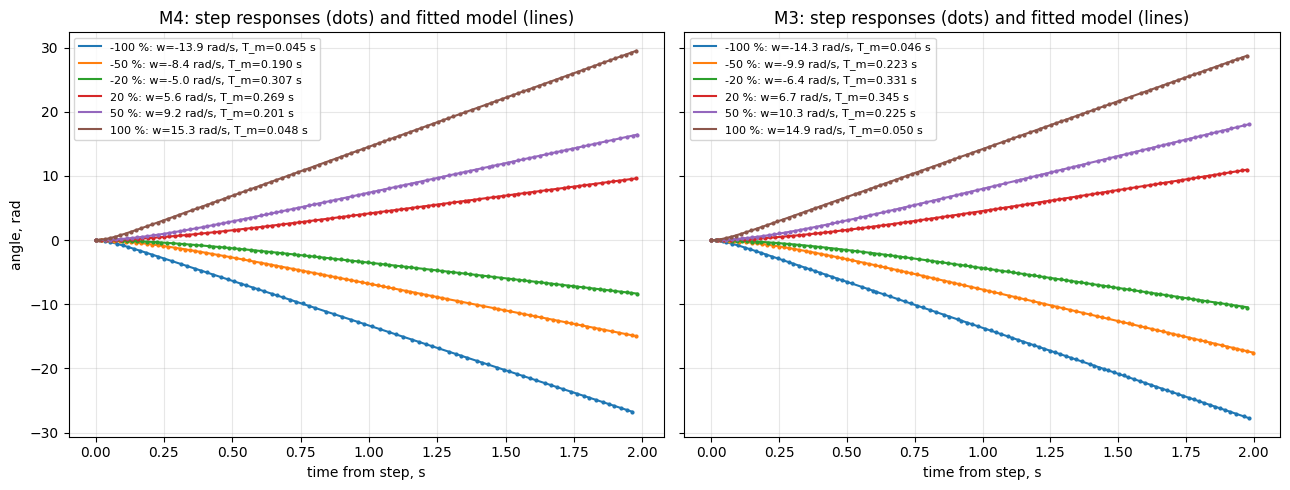

In [5]:
show = [-100, -50, -20, 20, 50, 100]
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, k in zip(axs, ['M4', 'M3']):
    for r in steps[k]:
        if r['level'] in show:
            line, = ax.plot(r['t'], r['th'], '.', ms=4)
            tt = np.linspace(0, r['t'][-1], 200)
            ax.plot(tt, model(tt, r['w'], r['T']), '-', color=line.get_color(), lw=1.5,
                    label=f"{r['level']:.0f} %: w={r['w']:.1f} rad/s, T_m={r['T']:.3f} s")
    ax.set_title(f'{k}: step responses (dots) and fitted model (lines)')
    ax.set_xlabel('time from step, s')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axs[0].set_ylabel('angle, rad')
plt.tight_layout()
plt.show()

### 4.3 Speed and time constant versus PWM

For each motor and direction I fit a straight line $|\omega_{ss}| = a\,|\text{PWM}| + b$ to the linear part, $|\text{PWM}| \ge 30\%$. With $U = \text{PWM}/100 \cdot U_{battery}$ the slope gives $k_e = U_{battery} / (100\,a)$. The dead zone is taken from the fine series: the levels where the wheel did not move.

In [6]:
LIN_MIN = 30

def direction(rows, rows_fine, sign):
    r = [x for x in rows if np.sign(x['level']) == sign]
    lv = np.abs([x['level'] for x in r])
    w = np.abs([x['w'] for x in r])
    T = np.array([x['T'] for x in r])
    lin = lv >= LIN_MIN
    a, b = np.polyfit(lv[lin], w[lin], 1)
    rf = [x for x in rows_fine if np.sign(x['level']) == sign]
    lvf = np.abs([x['level'] for x in rf])
    wf = np.abs([x['w'] for x in rf])
    mf = np.array([x['moved'] for x in rf])
    stuck = lvf[~mf]
    dz = stuck.max() if len(stuck) else 0
    return dict(lv=lv, w=w, T=T, a=a, b=b, lvf=lvf, wf=wf, movedf=mf, dz=dz,
                first_move=lvf[mf & (lvf > dz)].min(), T_mean=T.mean(), T_std=T.std())

par = {}
for k in steps:
    motor = k.split()[0]
    for name, sign in [('forward', 1), ('backward', -1)]:
        d = direction(steps[k], steps_fine[motor], sign)
        d['U'] = U_bat(step_files[k])
        d['k_e'] = d['U'] / (100 * d['a'])
        par[(k, name)] = d

print('motor      direction  no motion at  moves from  slope a, rad/s per %  b, rad/s  k_e, V*s/rad  mean T_m, s     U_bat, V')
for (k, name), d in par.items():
    nm = f"1..{d['dz']:.0f} %" if d['dz'] else 'none'
    print(f"{k:10s} {name:9s}  {nm:12s}  {d['first_move']:3.0f} %       {d['a']:.4f}                {d['b']:5.2f}     "
          f"{d['k_e']:.3f}         {d['T_mean']:.3f} ± {d['T_std']:.3f}   {d['U']:.1f}")

motor      direction  no motion at  moves from  slope a, rad/s per %  b, rad/s  k_e, V*s/rad  mean T_m, s     U_bat, V
M4         forward    none            1 %       0.1157                 3.42     0.968         0.149 ± 0.083   11.2
M4         backward   1..4 %          5 %       0.1062                 3.08     1.054         0.175 ± 0.096   11.2
M4 repeat  forward    none            1 %       0.1148                 3.55     0.976         0.179 ± 0.081   11.2
M4 repeat  backward   1..4 %          5 %       0.1086                 2.90     1.031         0.168 ± 0.118   11.2
M3         forward    none            1 %       0.0940                 5.54     1.191         0.207 ± 0.108   11.2
M3         backward   none            1 %       0.0915                 5.21     1.224         0.193 ± 0.108   11.2


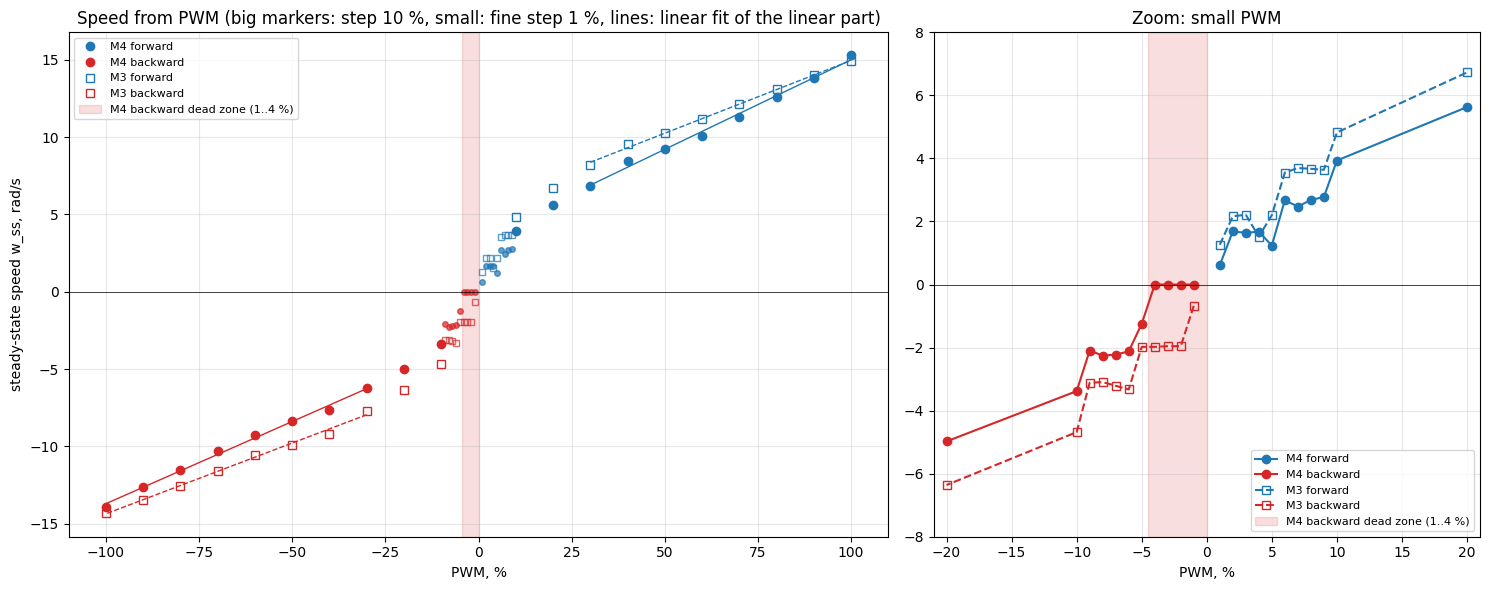

In [7]:
colors = {'forward': 'tab:blue', 'backward': 'tab:red'}
marks = {'M4': 'o', 'M3': 's'}
fig, (ax, axz) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 2]})
for k in ['M4', 'M3']:
    for name, sign in [('forward', 1), ('backward', -1)]:
        d = par[(k, name)]
        style = dict(color=colors[name], mfc='none' if k == 'M3' else colors[name])
        ax.plot(sign * d['lv'], sign * d['w'], marks[k], label=f'{k} {name}', **style)
        ax.plot(sign * d['lvf'], sign * d['wf'], marks[k], ms=4, alpha=0.7, **style)
        x = np.linspace(LIN_MIN, 100, 10)
        ax.plot(sign * x, sign * (d['a'] * x + d['b']), '--' if k == 'M3' else '-', color=colors[name], lw=1)
        xs = np.r_[d['lvf'], d['lv'][d['lv'] <= 20]]
        ys = np.r_[d['wf'], d['w'][d['lv'] <= 20]]
        o = np.argsort(xs)
        axz.plot(sign * xs[o], sign * ys[o], marks[k] + ('--' if k == 'M3' else '-'), label=f'{k} {name}', **style)
for a_ in (ax, axz):
    dz4 = par[('M4', 'backward')]['dz']
    a_.axvspan(-dz4 - 0.5, 0, color='tab:red', alpha=0.15, label=f'M4 backward dead zone (1..{dz4:.0f} %)')
    a_.axhline(0, color='k', lw=0.5)
    a_.set_xlabel('PWM, %')
    a_.grid(alpha=0.3)
ax.set_ylabel('steady-state speed w_ss, rad/s')
ax.set_title('Speed from PWM (big markers: step 10 %, small: fine step 1 %, lines: linear fit of the linear part)')
axz.set_xlim(-21, 21)
axz.set_ylim(-8, 8)
axz.set_title('Zoom: small PWM')
ax.legend(fontsize=8)
axz.legend(fontsize=8)
plt.tight_layout()
plt.show()

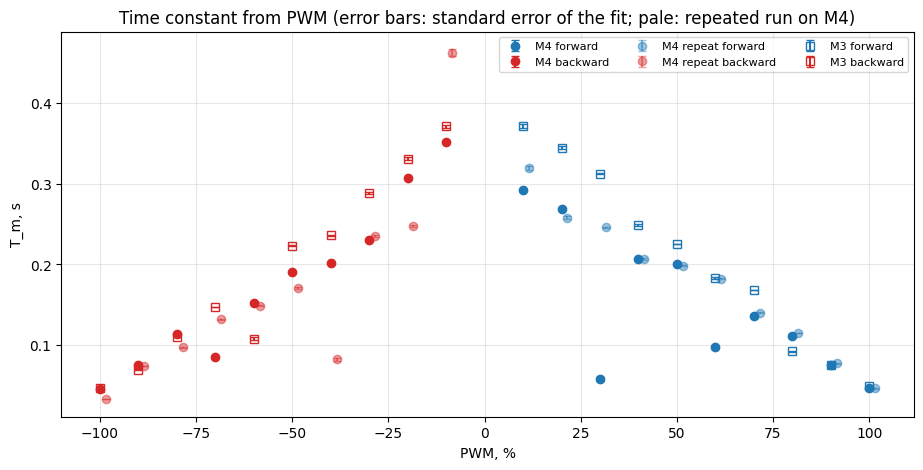

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
for k, kk, alpha in [('M4', 'M4', 1), ('M4 repeat', 'M4', 0.45), ('M3', 'M3', 1)]:
    for name, sign in [('forward', 1), ('backward', -1)]:
        r = [x for x in steps[k] if np.sign(x['level']) == sign]
        ax.errorbar([x['level'] + (1.5 if 'repeat' in k else 0) for x in r], [x['T'] for x in r],
                    yerr=[x['T_err'] for x in r], fmt=marks[kk], color=colors[name], alpha=alpha,
                    mfc='none' if kk == 'M3' else colors[name], capsize=3, label=f'{k} {name}')
ax.set_xlabel('PWM, %')
ax.set_ylabel('T_m, s')
ax.set_title('Time constant from PWM (error bars: standard error of the fit; pale: repeated run on M4)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=3)
plt.show()

### 4.4 Complex signals: model versus real motor

The identified parameters are used to simulate the motor with the recorded input. In the course notebook `u` is a constant; here it is a function of time, interpolated from the logged PWM (converted to volts).

* **Model A (no dead zone):** the pure first-order model, $\omega_{ss} = U/k_e$ with one $k_e$ (mean of both directions) and the mean $T_m$.
* **Model B (with dead zone):** the same dynamics, but the steady-state speed follows the fitted line of each direction, $\omega_{ss} = \text{sgn}(U)\,(a|\text{PWM}| + b)$ (so $k_e$ and the offset are different for forward and backward), and the motor does not move inside the dead zone found in the fine series.
* **Model C (measured curve, extra):** $\omega_{ss}$ is interpolated directly from all measured step points (fine + coarse). This shows how much of the error comes from the static curve and how much from the dynamics.

All three use $\dot\omega = (\omega_{ss}(U) - \omega)/T_m$, which is the notebook's equation 5 with $\omega_{ss} = U/k_e$ for model A.

The measured speed is the numerical derivative of the angle (`np.gradient`) smoothed with a moving average of **5 samples** (≈ 0.14 s).

In [9]:
WINDOW = 5

def smooth(x, n=WINDOW):
    return np.convolve(x, np.ones(n) / n, mode='same')

def simulate(t_log, U_log, T_m, w_ss_of_U):
    def motor(state, t):
        speed, angle = state
        u = np.interp(t, t_log, U_log)
        return np.array([-speed / T_m + w_ss_of_U(u) / T_m, speed])
    y = odeint(motor, [0, 0], t_log, hmax=0.01)
    return y[:, 1], y[:, 0]

def fit_percent(y, yhat):
    return 100 * (1 - np.linalg.norm(y - yhat) / np.linalg.norm(y - np.mean(y)))

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def models(k, U_battery):
    f, b = par[(k, 'forward')], par[(k, 'backward')]
    T_m = (f['T_mean'] + b['T_mean']) / 2
    k_mean = (f['k_e'] + b['k_e']) / 2
    dz_f, dz_b = f['dz'] + 0.5, b['dz'] + 0.5
    def model_A(u):
        return u / k_mean
    def model_B(u):
        p = 100 * u / U_battery
        if p > dz_f:
            return f['a'] * p + f['b']
        if p < -dz_b:
            return -(b['a'] * -p + b['b'])
        return 0.0
    lv = np.r_[-b['lv'], -b['lvf'], 0, f['lvf'], f['lv']]
    ws = np.r_[-b['w'], -b['wf'], 0, f['wf'], f['w']]
    order = np.argsort(lv)
    lv, ws = lv[order], ws[order]
    def model_C(u):
        return np.interp(100 * u / U_battery, lv, ws)
    return T_m, model_A, model_B, model_C, dict(T_m=T_m, k_mean=k_mean, lv=lv, ws=ws)

results = {}
for name in signal_files:
    k = name.split('_')[1][:2]
    th, t, pwm = load(name)
    th, t = th - th[0], t - t[0]
    U = pwm / 100 * U_bat(name)
    T_m, mA, mB, mC, p = models(k, U_bat(name))
    thA, wA = simulate(t, U, T_m, mA)
    thB, wB = simulate(t, U, T_m, mB)
    thC, wC = simulate(t, U, T_m, mC)
    w = smooth(np.gradient(th, t))
    results[name] = dict(t=t, th=th, w=w, pwm=pwm, U=U, thA=thA, wA=wA, thB=thB, wB=wB, thC=thC, wC=wC, p=p)

print('fit % (higher is better) and RMSE')
print('signal          angle fit A / B / C         speed fit A / B / C        RMSE B: angle, rad   speed, rad/s')
for name, r in results.items():
    fa = [fit_percent(r['th'], r['th' + m]) for m in 'ABC']
    fw = [fit_percent(r['w'], smooth(r['w' + m])) for m in 'ABC']
    print(f"{name:14s}  {fa[0]:6.1f} / {fa[1]:6.1f} / {fa[2]:6.1f}     {fw[0]:6.1f} / {fw[1]:6.1f} / {fw[2]:6.1f}"
          f"        {rmse(r['th'], r['thB']):6.2f}          {rmse(r['w'], smooth(r['wB'])):6.2f}")

fit % (higher is better) and RMSE
signal          angle fit A / B / C         speed fit A / B / C        RMSE B: angle, rad   speed, rad/s
square_M4.txt    -98.4 /   53.6 /   67.6       67.5 /   90.9 /   91.4          0.57            0.50
square_M3.txt    -58.7 /   64.7 /   54.7       46.8 /   85.9 /   85.4          0.56            0.85
chirp_M4.txt    -130.8 /   -5.2 /   26.7       48.1 /   62.4 /   63.1          1.33            1.19
chirp_M3.txt    -138.7 /  -95.8 /  -47.3       39.9 /   64.9 /   67.2          2.19            1.11


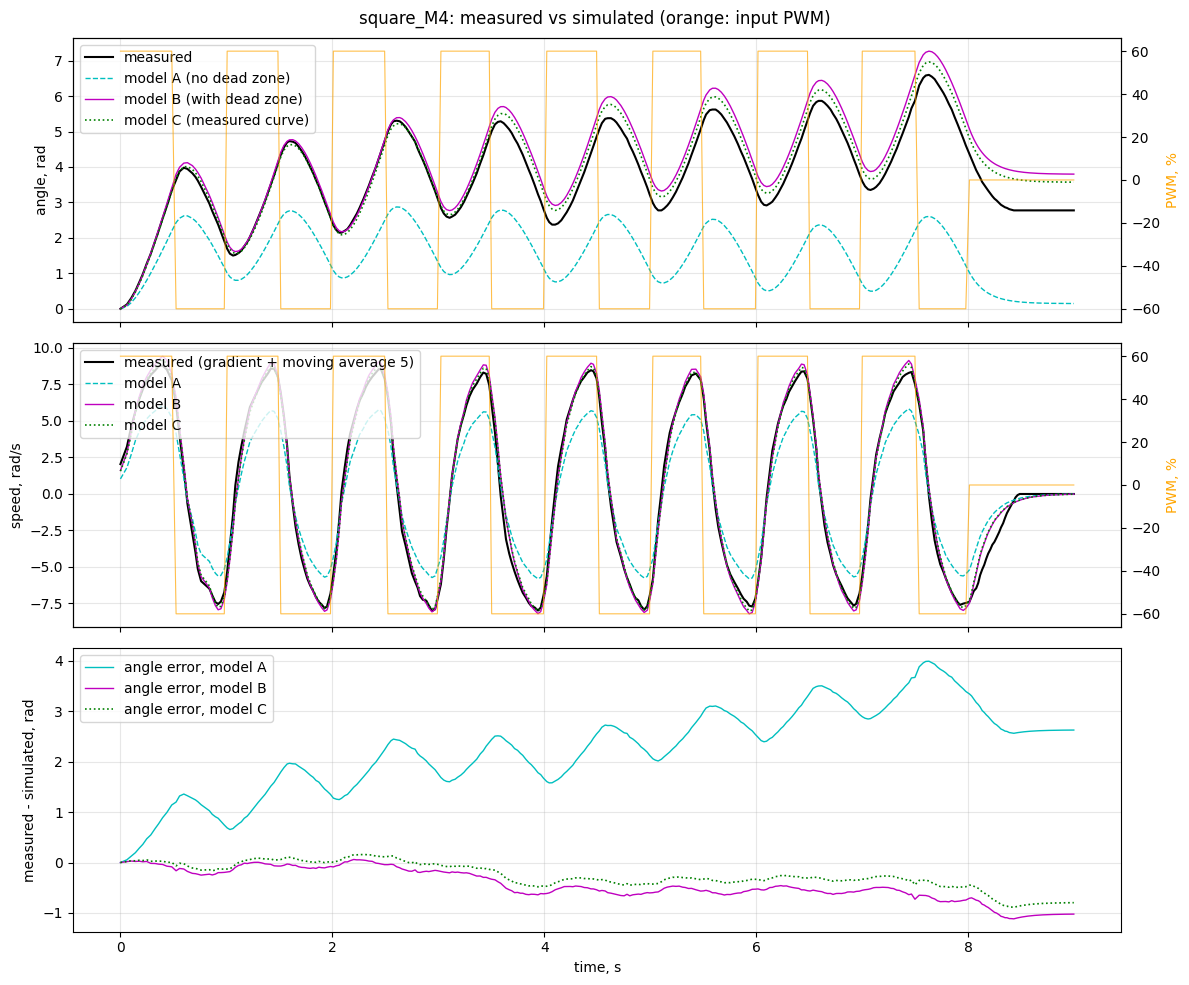

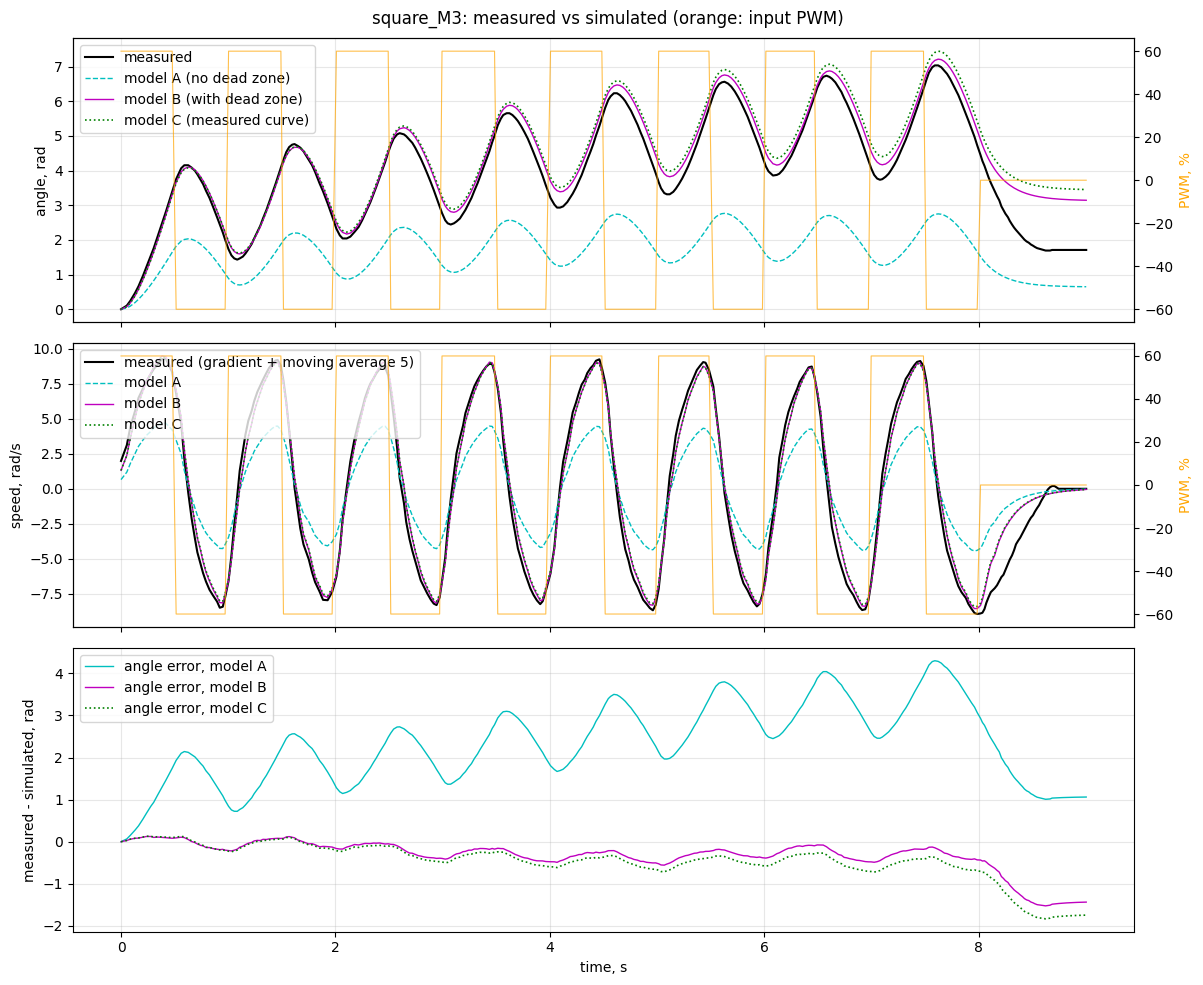

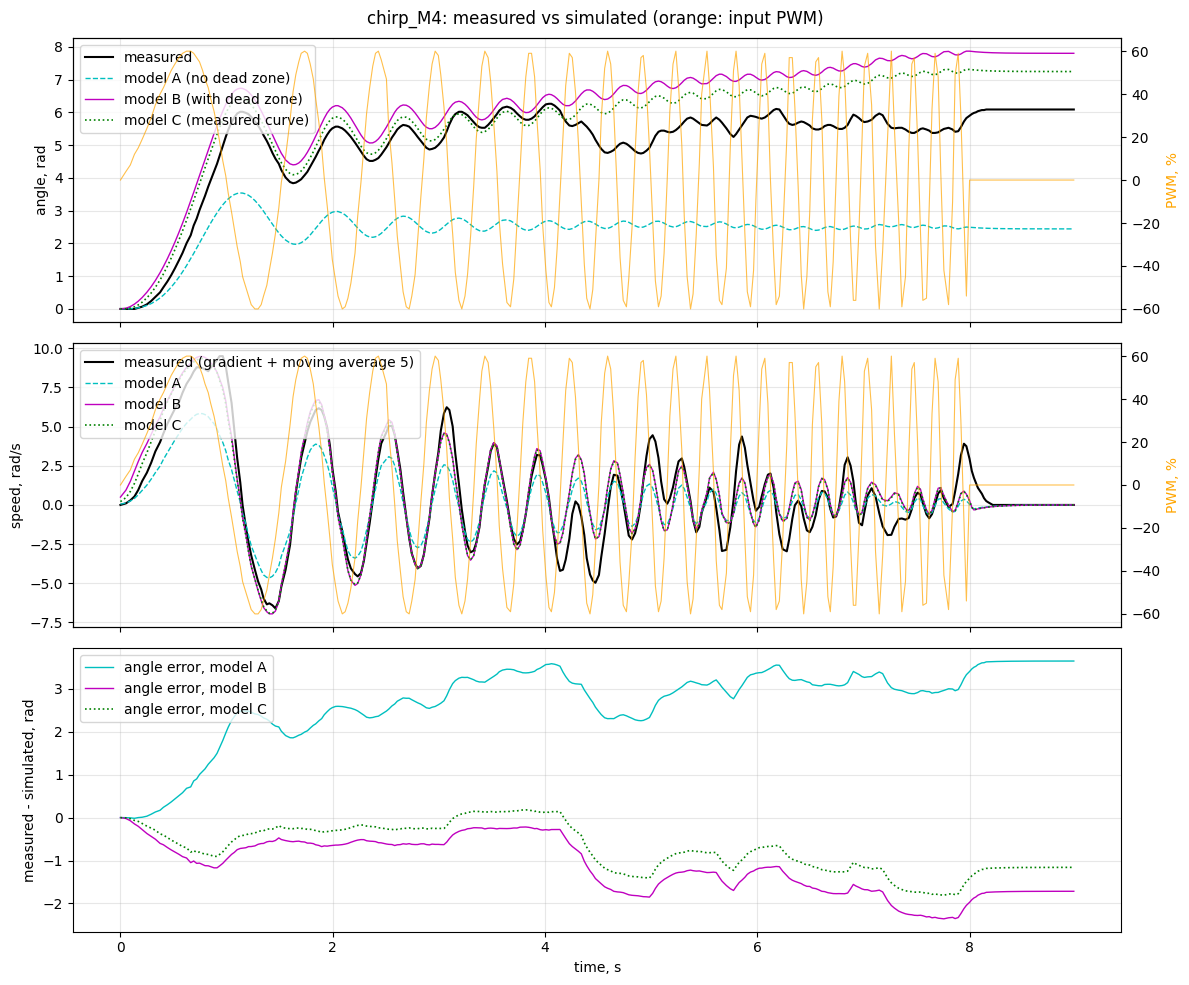

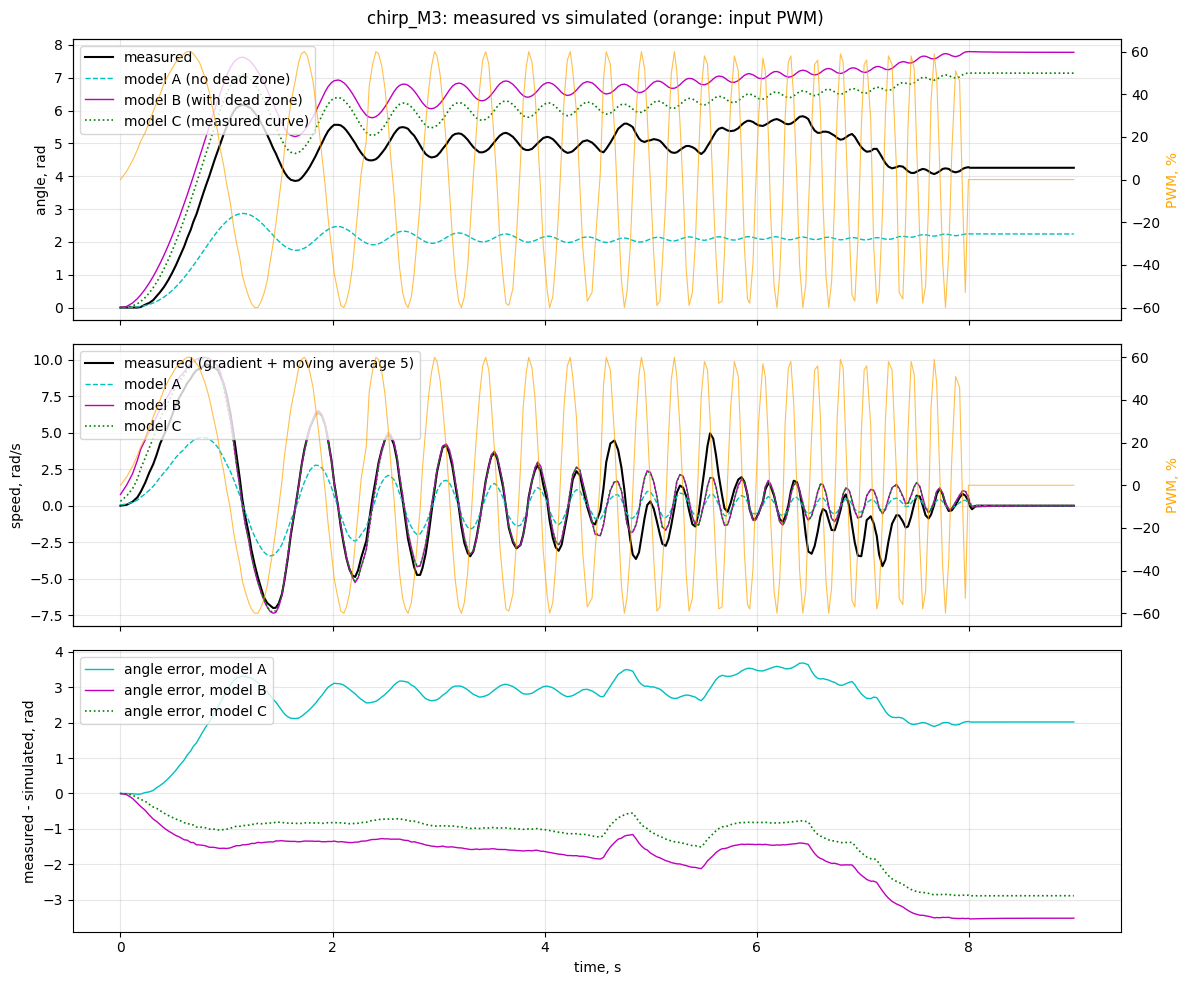

In [10]:
def plot_complex(name):
    r = results[name]
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    ax1.plot(r['t'], r['th'], 'k-', lw=1.5, label='measured')
    ax1.plot(r['t'], r['thA'], 'c--', lw=1, label='model A (no dead zone)')
    ax1.plot(r['t'], r['thB'], 'm-', lw=1, label='model B (with dead zone)')
    ax1.plot(r['t'], r['thC'], 'g:', lw=1.2, label='model C (measured curve)')
    ax1.set_ylabel('angle, rad')
    ax1.legend(loc='upper left')
    ax2.plot(r['t'], r['w'], 'k-', lw=1.5, label=f'measured (gradient + moving average {WINDOW})')
    ax2.plot(r['t'], smooth(r['wA']), 'c--', lw=1, label='model A')
    ax2.plot(r['t'], smooth(r['wB']), 'm-', lw=1, label='model B')
    ax2.plot(r['t'], smooth(r['wC']), 'g:', lw=1.2, label='model C')
    ax2.set_ylabel('speed, rad/s')
    ax2.legend(loc='upper left')
    for ax in (ax1, ax2):
        axp = ax.twinx()
        axp.plot(r['t'], r['pwm'], color='orange', lw=0.8, alpha=0.7)
        axp.set_ylabel('PWM, %', color='orange')
        ax.grid(alpha=0.3)
    ax3.plot(r['t'], r['th'] - r['thA'], 'c-', lw=1, label='angle error, model A')
    ax3.plot(r['t'], r['th'] - r['thB'], 'm-', lw=1, label='angle error, model B')
    ax3.plot(r['t'], r['th'] - r['thC'], 'g:', lw=1.2, label='angle error, model C')
    ax3.set_ylabel('measured - simulated, rad')
    ax3.set_xlabel('time, s')
    ax3.grid(alpha=0.3)
    ax3.legend(loc='upper left')
    fig.suptitle(name.replace('.txt', '') + ': measured vs simulated (orange: input PWM)')
    plt.tight_layout()
    plt.show()

for name in results:
    plot_complex(name)

**Chirp: frequency response.** The chirp is cut into single periods. In each period I fit $c_0 + c_1 t + a\sin(2\pi f t) + b\cos(2\pi f t)$ at the local frequency $f$, both to the angle and to the logged PWM. The speed amplitude is $2\pi f\sqrt{a^2+b^2}$ of the angle fit, which avoids differentiating the noisy angle. The ratio speed amplitude / input amplitude (in volts) is compared with the first-order model $1/(k_e\sqrt{1+(2\pi f T_m)^2})$ and with the same analysis done on the simulated angle (model C).

chirp_M4.txt: k_e from slope 1.011, U/w_ss at 60 %: 0.666 V*s/rad, mean T_m 0.162 s, corner frequency 1/(2 pi T_m) = 0.98 Hz
chirp_M3.txt: k_e from slope 1.207, U/w_ss at 60 %: 0.604 V*s/rad, mean T_m 0.200 s, corner frequency 1/(2 pi T_m) = 0.79 Hz


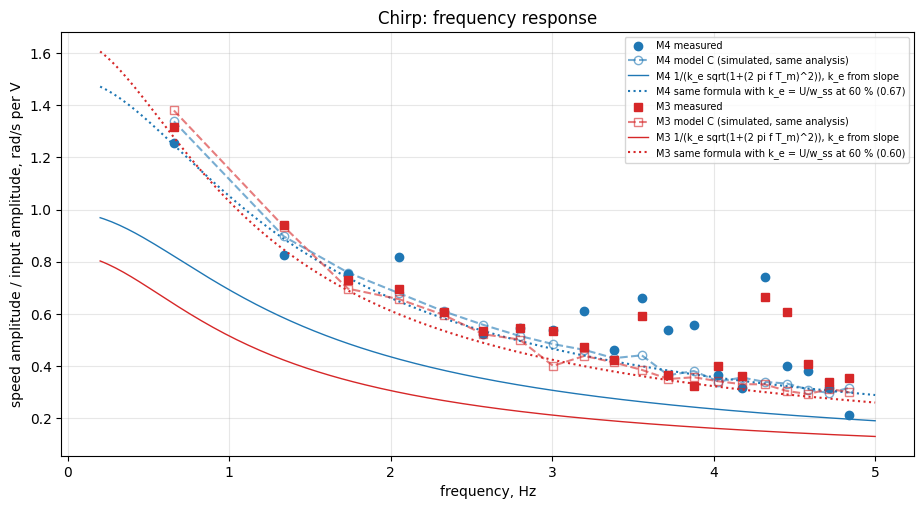

In [11]:
F0, F1, TCH = 0.2, 5.0, 8.0

def chirp_response(t, y):
    rate = (F1 - F0) / TCH
    n_cycles = int(F0 * TCH + rate * TCH ** 2 / 2)
    out = []
    for c in range(n_cycles):
        t_a = (-F0 + np.sqrt(F0 ** 2 + 2 * rate * c)) / rate
        t_b = (-F0 + np.sqrt(F0 ** 2 + 2 * rate * (c + 1))) / rate
        m = (t >= t_a) & (t < t_b)
        if m.sum() < 5:
            continue
        f = 1 / (t_b - t_a)
        tt = t[m] - t_a
        X = np.column_stack([np.ones_like(tt), tt, np.sin(2 * np.pi * f * tt), np.cos(2 * np.pi * f * tt)])
        coef = np.linalg.lstsq(X, y[m], rcond=None)[0]
        out.append((f, np.hypot(coef[2], coef[3])))
    return np.array(out)

fig, ax = plt.subplots(figsize=(11, 5.5))
chirp_table = {}
for name, mk, col in [('chirp_M4.txt', 'o', 'tab:blue'), ('chirp_M3.txt', 's', 'tab:red')]:
    r = results[name]
    k = name[6:8]
    U_amp = chirp_response(r['t'], r['U'])[:, 1]
    meas = chirp_response(r['t'], r['th'])
    sim = chirp_response(r['t'], r['thC'])
    f = meas[:, 0]
    ratio_meas = 2 * np.pi * f * meas[:, 1] / U_amp
    ratio_sim = 2 * np.pi * f * sim[:, 1] / U_amp
    chirp_table[name] = (f, ratio_meas, ratio_sim)
    ax.plot(f, ratio_meas, mk, color=col, label=f'{k} measured')
    ax.plot(f, ratio_sim, mk + '--', color=col, mfc='none', alpha=0.6, label=f'{k} model C (simulated, same analysis)')
    p = r['p']
    ff = np.linspace(0.2, 5, 200)
    ax.plot(ff, 1 / (p['k_mean'] * np.sqrt(1 + (2 * np.pi * ff * p['T_m']) ** 2)), '-', color=col, lw=1,
            label=f'{k} 1/(k_e sqrt(1+(2 pi f T_m)^2)), k_e from slope')
    U60 = 0.6 * U_bat(name)
    k_eff = U60 / np.interp(60, p['lv'], p['ws'])
    ax.plot(ff, 1 / (k_eff * np.sqrt(1 + (2 * np.pi * ff * p['T_m']) ** 2)), ':', color=col, lw=1.5,
            label=f'{k} same formula with k_e = U/w_ss at 60 % ({k_eff:.2f})')
    print(f"{name}: k_e from slope {p['k_mean']:.3f}, U/w_ss at 60 %: {k_eff:.3f} V*s/rad, mean T_m {p['T_m']:.3f} s, "
          f"corner frequency 1/(2 pi T_m) = {1 / (2 * np.pi * p['T_m']):.2f} Hz")
ax.set_xlabel('frequency, Hz')
ax.set_ylabel('speed amplitude / input amplitude, rad/s per V')
ax.set_title('Chirp: frequency response')
ax.grid(alpha=0.3)
ax.legend(fontsize=7)
plt.show()

## 5. Artifact analysis

In [12]:
print('Forward vs backward asymmetry (backward relative to forward):')
for k in ['M4', 'M3']:
    f, b = par[(k, 'forward')], par[(k, 'backward')]
    w100 = (b['w'][b['lv'] == 100][0] / f['w'][f['lv'] == 100][0] - 1) * 100
    print(f"  {k}: slope {100 * (b['a'] / f['a'] - 1):+.1f} %, k_e {100 * (b['k_e'] / f['k_e'] - 1):+.1f} %, "
          f"w_ss at 100 % {w100:+.1f} %, mean T_m {100 * (b['T_mean'] / f['T_mean'] - 1):+.1f} %, "
          f"starts to move: forward {f['first_move']:.0f} %, backward {b['first_move']:.0f} %")

print('\nMotor-to-motor spread (M3 relative to M4):')
for name in ['forward', 'backward']:
    a, b = par[('M4', name)], par[('M3', name)]
    w50 = (b['w'][b['lv'] == 50][0] / a['w'][a['lv'] == 50][0] - 1) * 100
    w100 = (b['w'][b['lv'] == 100][0] / a['w'][a['lv'] == 100][0] - 1) * 100
    print(f"  {name}: slope {100 * (b['a'] / a['a'] - 1):+.1f} %, k_e {100 * (b['k_e'] / a['k_e'] - 1):+.1f} %, "
          f"w_ss at 50 % {w50:+.1f} %, at 100 % {w100:+.1f} %, mean T_m {100 * (b['T_mean'] / a['T_mean'] - 1):+.1f} %")

print('\nSaturation (measured |w_ss| minus linear fit at the top levels, rad/s):')
for (k, name), d in par.items():
    top = d['lv'] >= 80
    print(f"  {k:10s} {name:9s}", ', '.join(f"{lv:.0f}%: {w - (d['a'] * lv + d['b']):+.2f}"
                                            for lv, w in zip(d['lv'][top], d['w'][top])))

print('\nSmall PWM (fine series): w_ss in rad/s')
for k in ['M4', 'M3']:
    print(f'  {k}: ' + '  '.join(f"{r['level']:+.0f}%: {r['w']:.2f}" for r in steps_fine[k]))

Forward vs backward asymmetry (backward relative to forward):
  M4: slope -8.2 %, k_e +9.0 %, w_ss at 100 % -8.8 %, mean T_m +17.4 %, starts to move: forward 1 %, backward 5 %
  M3: slope -2.7 %, k_e +2.8 %, w_ss at 100 % -4.0 %, mean T_m -6.7 %, starts to move: forward 1 %, backward 1 %

Motor-to-motor spread (M3 relative to M4):
  forward: slope -18.7 %, k_e +23.1 %, w_ss at 50 % +11.4 %, at 100 % -2.3 %, mean T_m +38.7 %
  backward: slope -13.9 %, k_e +16.1 %, w_ss at 50 % +18.1 %, at 100 % +2.8 %, mean T_m +10.2 %

Saturation (measured |w_ss| minus linear fit at the top levels, rad/s):
  M4         forward   80%: -0.12, 90%: -0.03, 100%: +0.29
  M4         backward  100%: +0.25, 90%: -0.02, 80%: -0.08
  M4 repeat  forward   80%: -0.11, 90%: -0.05, 100%: +0.29
  M4 repeat  backward  100%: +0.19, 90%: -0.03, 80%: -0.05
  M3         forward   80%: +0.02, 90%: -0.02, 100%: -0.02
  M3         backward  100%: -0.02, 90%: -0.01, 80%: +0.04

Small PWM (fine series): w_ss in rad/s
  M4: -9%

In [13]:
print('Zero drift')
for k, (th, t, pwm) in list(data.items()) + [(k + ' fine', v) for k, v in fine.items()]:
    s, e = split(pwm)[0]
    last = []
    for s2, e2 in split(pwm)[1:]:
        if pwm[s2] == 0:
            m = t[s2:e2] > t[e2 - 1] - 0.2
            last.append(np.degrees(th[s2:e2][m].max() - th[s2:e2][m].min()))
    print(f"  {k:10s} first time() value {t[0] * 1000:3.0f} ms; encoder with the motor off at the start "
          f"({t[e - 1] - t[0]:.1f} s): {np.degrees(th[s:e]).min():.0f}..{np.degrees(th[s:e]).max():.0f} deg; "
          f"last 0.2 s of each coasting segment: max change {max(last):.0f} deg")

Zero drift
  M4         first time() value  36 ms; encoder with the motor off at the start (3.0 s): 0..0 deg; last 0.2 s of each coasting segment: max change 0 deg
  M4 repeat  first time() value  59 ms; encoder with the motor off at the start (3.0 s): 0..0 deg; last 0.2 s of each coasting segment: max change 0 deg
  M3         first time() value  42 ms; encoder with the motor off at the start (3.0 s): 0..0 deg; last 0.2 s of each coasting segment: max change 7 deg
  M4 fine    first time() value  27 ms; encoder with the motor off at the start (3.0 s): 0..0 deg; last 0.2 s of each coasting segment: max change 0 deg
  M3 fine    first time() value  43 ms; encoder with the motor off at the start (3.0 s): 0..0 deg; last 0.2 s of each coasting segment: max change 0 deg


In [14]:
def coast_fit(theta, t, pwm):
    out = []
    segs = split(pwm)
    for i, (s, e) in enumerate(segs):
        if i == 0 or pwm[s] != 0:
            continue
        level = pwm[segs[i - 1][0]]
        x = t[s:e] - t[s]
        y = theta[s:e] - theta[s]
        decay = lambda tt, w0, Tc: w0 * Tc * (1 - np.exp(-tt / Tc))
        (w0, Tc), _ = optimize.curve_fit(decay, x, y, p0=[np.sign(level) * 5, 0.2], bounds=([-60, 0.01], [60, 3]))
        out.append((level, y[-1], Tc))
    return np.array(out)

print('Coasting after power-off (1 s with PWM = 0)')
coast = {}
for k in ['M4', 'M3']:
    c = coast_fit(*data[k])
    coast[k] = c
    w = {r['level']: r['w'] for r in steps[k]}
    T = {r['level']: r['T'] for r in steps[k]}
    print(f"  {k}: coasting time constant T_c = {c[:, 2].mean():.3f} s (from {c[:, 2].min():.2f} to {c[:, 2].max():.2f} s)")
    for lv, ang, Tc in c:
        if abs(lv) in (20, 50, 100):
            print(f"      after {lv:+4.0f} %: wheel turned {ang:+5.2f} rad after power-off; "
                  f"first-order model with T_m predicts w_ss*T_m = {w[lv] * T[lv]:+5.2f} rad")

Coasting after power-off (1 s with PWM = 0)


  M4: coasting time constant T_c = 0.198 s (from 0.08 to 0.32 s)
      after -100 %: wheel turned -4.07 rad after power-off; first-order model with T_m predicts w_ss*T_m = -0.63 rad
      after  -50 %: wheel turned -1.83 rad after power-off; first-order model with T_m predicts w_ss*T_m = -1.59 rad
      after  -20 %: wheel turned -0.72 rad after power-off; first-order model with T_m predicts w_ss*T_m = -1.53 rad
      after  +20 %: wheel turned +1.03 rad after power-off; first-order model with T_m predicts w_ss*T_m = +1.51 rad
      after  +50 %: wheel turned +2.39 rad after power-off; first-order model with T_m predicts w_ss*T_m = +1.85 rad
      after +100 %: wheel turned +3.37 rad after power-off; first-order model with T_m predicts w_ss*T_m = +0.73 rad
  M3: coasting time constant T_c = 0.292 s (from 0.13 to 0.43 s)
      after -100 %: wheel turned -5.20 rad after power-off; first-order model with T_m predicts w_ss*T_m = -0.67 rad
      after  -50 %: wheel turned -3.09 rad after po

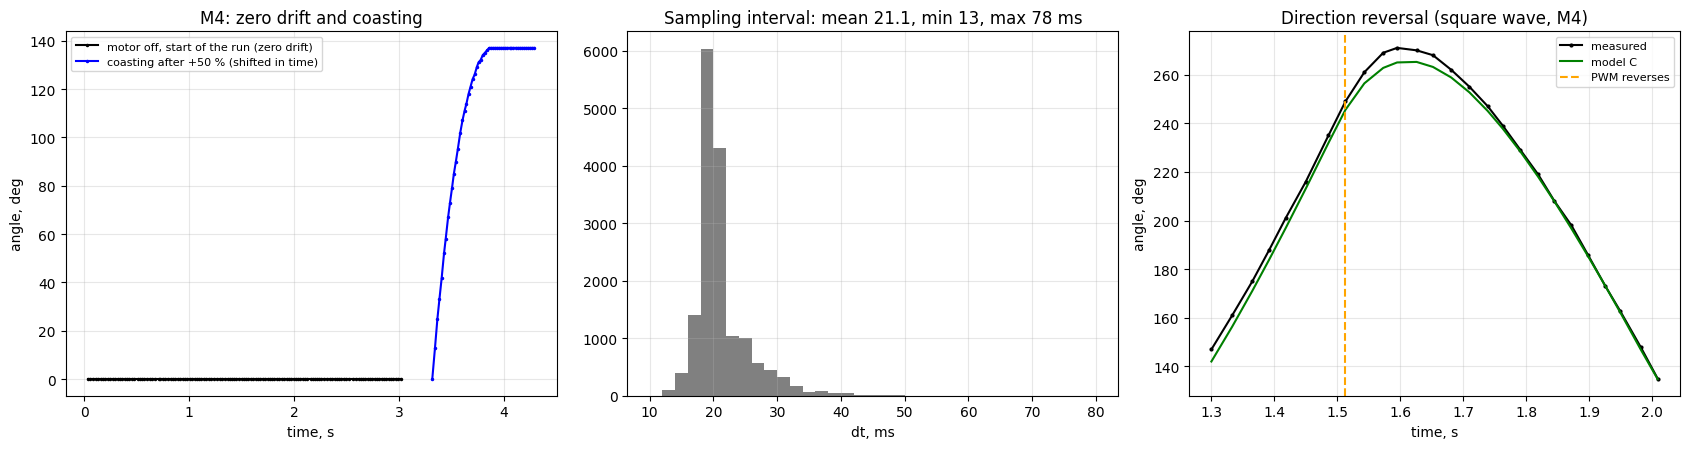

steps_M4.txt    sampling interval: mean 20.5 ms, min 13 ms, max 52 ms
square_M4.txt   sampling interval: mean 27.6 ms, min 16 ms, max 78 ms


In [15]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
th, t, pwm = data['M4']
s, e = split(pwm)[0]
axs[0].plot(t[s:e], np.degrees(th[s:e]), 'k.-', ms=3, label='motor off, start of the run (zero drift)')
r = [x for x in steps['M4'] if x['level'] == 50][0]
s3, e3 = [x for x in split(pwm) if x[0] == r['end']][0]
axs[0].plot(t[s3:e3] - t[s3] + t[e - 1] + 0.3, np.degrees(th[s3:e3] - th[s3]), 'b.-', ms=3,
            label='coasting after +50 % (shifted in time)')
axs[0].set_title('M4: zero drift and coasting')
axs[0].set_xlabel('time, s')
axs[0].set_ylabel('angle, deg')
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3)

all_files = list(step_files.values()) + list(fine_files.values()) + signal_files
dts = np.concatenate([np.diff(load(f)[1]) * 1000 for f in all_files])
axs[1].hist(dts, bins=np.arange(10, 82, 2), color='grey')
axs[1].set_title(f'Sampling interval: mean {dts.mean():.1f}, min {dts.min():.0f}, max {dts.max():.0f} ms')
axs[1].set_xlabel('dt, ms')
axs[1].grid(alpha=0.3)

rq = results['square_M4.txt']
rev = np.flatnonzero(np.diff(np.sign(rq['pwm'])) != 0) + 1
i = rev[2]
m = (rq['t'] > rq['t'][i] - 0.25) & (rq['t'] < rq['t'][i] + 0.5)
axs[2].plot(rq['t'][m], np.degrees(rq['th'][m]), 'k.-', ms=4, label='measured')
axs[2].plot(rq['t'][m], np.degrees(rq['thC'][m]), 'g-', label='model C')
axs[2].axvline(rq['t'][i], color='orange', ls='--', label='PWM reverses')
axs[2].set_title('Direction reversal (square wave, M4)')
axs[2].set_xlabel('time, s')
axs[2].set_ylabel('angle, deg')
axs[2].legend(fontsize=8)
axs[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

for f in ['steps_M4.txt', 'square_M4.txt']:
    d = np.diff(load(f)[1]) * 1000
    print(f'{f:15s} sampling interval: mean {d.mean():.1f} ms, min {d.min():.0f} ms, max {d.max():.0f} ms')

In [16]:
print('Backlash: delay from the PWM reversal to the turning point of the angle')
for name in ['square_M4.txt', 'square_M3.txt']:
    rq = results[name]
    rev = np.flatnonzero(np.diff(np.sign(rq['pwm'])) != 0) + 1
    d_meas, d_sim = [], []
    for i in rev[1:]:
        m = (rq['t'] >= rq['t'][i - 1]) & (rq['t'] < rq['t'][i] + 0.4)
        idx = np.flatnonzero(m)
        sgn = np.sign(rq['pwm'][i - 1])
        d_meas.append(rq['t'][idx[np.argmax(sgn * rq['th'][idx])]] - rq['t'][i - 1])
        d_sim.append(rq['t'][idx[np.argmax(sgn * rq['thC'][idx])]] - rq['t'][i - 1])
    print(f'  {name}: measured {1000 * np.mean(d_meas):.0f} ms, model {1000 * np.mean(d_sim):.0f} ms, '
          f'difference {1000 * (np.mean(d_meas) - np.mean(d_sim)):+.0f} ms')

Backlash: delay from the PWM reversal to the turning point of the angle
  square_M4.txt: measured 124 ms, model 143 ms, difference -19 ms
  square_M3.txt: measured 132 ms, model 155 ms, difference -24 ms


In [17]:
print('Battery sag')
print('  ' + ', '.join(f'{f}: {u1:.1f} -> {u2:.1f} V' for f, (u1, u2) in battery.items()))

print('\nRepeatability (M4 repeat vs M4 run 1, same levels):')
a = {r['level']: r for r in steps['M4']}
b = {r['level']: r for r in steps['M4 repeat']}
dw = np.array([100 * (b[l]['w'] / a[l]['w'] - 1) for l in a])
dT = np.array([b[l]['T'] - a[l]['T'] for l in a])
seT = np.array([a[l]['T_err'] for l in a])
print(f'  w_ss: mean {dw.mean():+.1f} %, from {dw.min():+.1f} to {dw.max():+.1f} %; '
      f'|w_ss| difference above 20 %: max {np.abs(dw[np.abs(list(a)) > 20]).max():.1f} %')
print(f'  T_m: difference from {dT.min():+.3f} to {dT.max():+.3f} s, while the standard error of one fit is only '
      f'{np.median(seT):.3f} s')

r = [x for x in steps['M4'] if x['level'] == 50][0]
m = r['t'] > 1.0
w_raw = np.gradient(r['th'], r['t'])
print(f"\nDifferentiation noise in steady state (+50 %, last 1 s): std of raw gradient {w_raw[m].std():.2f} rad/s, "
      f"after moving average {WINDOW}: {smooth(w_raw)[m][WINDOW:-WINDOW].std():.2f} rad/s; "
      f"one encoder step (1 deg) in one sample = {np.radians(1) / np.mean(np.diff(r['t'])):.2f} rad/s")

Battery sag
  steps_M4.txt: 11.2 -> 11.2 V, steps_M4_repeat.txt: 11.2 -> 11.2 V, steps_M3.txt: 11.2 -> 11.2 V, square_M4.txt: 11.2 -> 11.2 V, square_M3.txt: 11.2 -> 11.2 V, chirp_M4.txt: 11.2 -> 11.2 V, chirp_M3.txt: 11.2 -> 11.2 V, deadzone_M4.txt: 11.2 -> 11.2 V, deadzone_M3.txt: 11.2 -> 11.2 V

Repeatability (M4 repeat vs M4 run 1, same levels):
  w_ss: mean +0.3 %, from -3.7 to +6.7 %; |w_ss| difference above 20 %: max 3.7 %
  T_m: difference from -0.120 to +0.188 s, while the standard error of one fit is only 0.001 s

Differentiation noise in steady state (+50 %, last 1 s): std of raw gradient 0.38 rad/s, after moving average 5: 0.17 rad/s; one encoder step (1 deg) in one sample = 0.87 rad/s


## 6. Report

### 6.1 Estimated values

**Left wheel — motor M4, encoder E4**

| Direction | Dead zone, % PWM | Slope, rad/s per % PWM | $k_e$, V·s/rad | Mean $T_m$, s | $U_{battery}$, V |
|---|---|---|---|---|---|
| Forward | none (moves from 1 %) | 0.116 | 0.97 | 0.15 ± 0.08 | 11.2 |
| Backward | 1 … 4 % (moves from 5 %) | 0.106 | 1.05 | 0.18 ± 0.10 | 11.2 |

Repeated run on M4: forward 0.115 rad/s per %, $k_e$ = 0.98, $T_m$ = 0.18 s; backward 0.109, $k_e$ = 1.03, $T_m$ = 0.17 s.

**Right wheel — motor M3, encoder E3**

| Direction | Dead zone, % PWM | Slope, rad/s per % PWM | $k_e$, V·s/rad | Mean $T_m$, s | $U_{battery}$, V |
|---|---|---|---|---|---|
| Forward | none (moves from 1 %) | 0.094 | 1.19 | 0.21 ± 0.11 | 11.2 |
| Backward | none (moves from 1 %) | 0.092 | 1.22 | 0.19 ± 0.11 | 11.2 |

Slope and $k_e$ come from the linear part ($|\text{PWM}| \ge 30\%$). The fitted line does not pass through zero: its offset is +3.1 … 3.4 rad/s for M4 and +5.2 … 5.5 rad/s for M3. $T_m$ is the mean ± standard deviation over the ten levels of one direction; it falls from about 0.3 s at 10 % to about 0.05 s at 100 %.

**Complex signals, model B (dead zone + line of each direction + mean $T_m$)**

| Signal | Speed fit | Angle fit | RMSE speed, rad/s | RMSE angle, rad |
|---|---|---|---|---|
| Square, M4 | 90.9 % | 53.6 % | 0.50 | 0.57 |
| Square, M3 | 85.9 % | 64.7 % | 0.85 | 0.56 |
| Chirp, M4 | 62.4 % | −5.2 % | 1.19 | 1.33 |
| Chirp, M3 | 64.9 % | −95.8 % | 1.11 | 2.19 |

### 6.2 Analysis

**How well does the first-order model describe the motor?** Every single step fits the first-order curve very well (in plot 1 the dots lie on the fitted line), but one constant $k_e$ and $T_m$ for the whole range is not enough. The speed is linear in PWM only above about 30 % and the line does not go through zero, so the simple model $\omega_{ss} = U/k_e$ is 30–50 % too slow at 60 %. With the dead zone and a separate line for each direction (model B) the speed fit on the square wave is 91 % for the left wheel and 86 % for the right wheel, but only 62–65 % on the chirp. The error is largest in the first second of the chirp, when the wheel starts from rest slower than the model. $T_m$ is not constant either: it falls from about 0.3 s at 10 % to 0.05 s at 100 % and changed by up to 0.19 s between two runs, so it is the weakest number of the model.

**Forward vs backward.** For the left motor (M4) the two directions are different: backward the slope is 8 % smaller, the mean $T_m$ is 17 % larger, and there is a small dead zone (−1 … −4 %) that forward does not have. For the right motor (M3) the difference is only 3–4 %. So a controller should use two sets of parameters at least for M4; for M3 one set is almost enough.

**Artifacts.** I found no zero drift: with the motor off the encoder stayed at 0 for 3 s. The dead zone exists only for M4 backward (1–4 %), and I did not see saturation or gear backlash. The biggest effects are coasting and the difference between the motors: after 100 % the wheel still turns 3.4 rad (M4) and 5.5 rad (M3), because PWM = 0 does not brake, and the right wheel is 11–18 % faster at 50 %. The sampling interval is 21 ms on average (13–52 ms) because the file is written every cycle, and the battery stayed at 11.2 V. For odometry the motor difference and the coasting matter most: with the same PWM the robot curves to the left and keeps moving after the stop, so the position has to be computed from the encoders, not from the PWM.

**Which complex signals and what they showed.** I used a square wave and a chirp. The square wave showed fast direction reversals from +60 % to −60 % and no backlash, and the model works best on it (speed fit 86–91 %). The chirp gave the frequency response: the speed amplitude falls from about 1.3 rad/s per V at 0.7 Hz to about 0.3 at 5 Hz, and it follows the first-order curve only if $k_e$ is taken at the signal amplitude, which shows again that the motor gain depends on the amplitude.
